<a href="https://colab.research.google.com/github/Symon-CNA/CNA/blob/main/PPC_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Programa para Casa #4 — Otimização Multidimensional

---
**Disciplina:** Cálculo Numérico Aplicado **Professor:** Prof. Dr. Rafael Gabler Gontijo

**Aluno:** Symon Souza - 242004312

# Comparando os métodos do Aclive Máximo e dos Gradientes Conjugados

Aqui serão implementados e comparados ambos os métodos de otimização multidimensional sem restrições:

1. método do **Aclive Máximo** (*Steepest Ascent*);
2. método dos **Gradientes Conjugados de Fletcher-Reeves**. Os dois métodos serão empregados na maximização da mesma função objetivo e utilizarão o mesmo procedimento de busca unidimensional baseado em interpolação quadrática de três pontos.

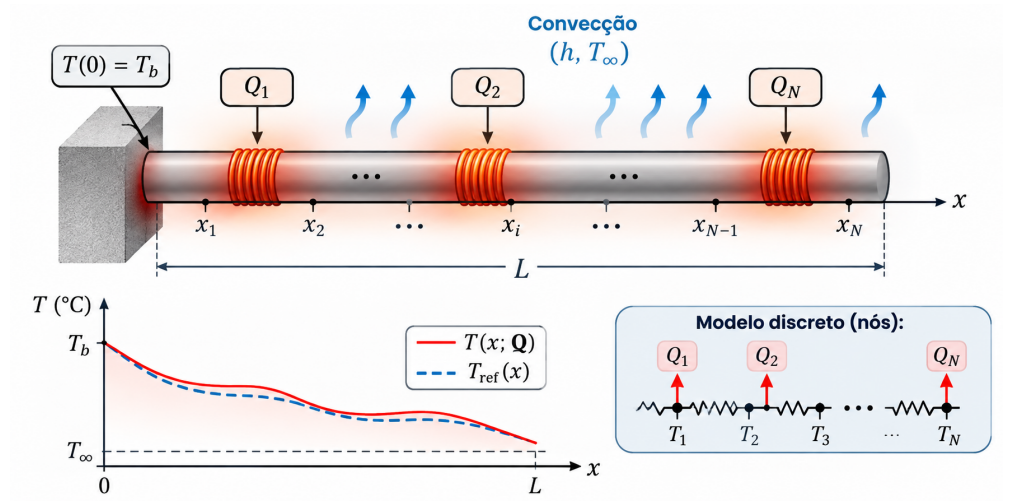

## 1. O Problema Físico e de Otimização

O objetivo deste trabalho é otimizar a distribuição de potência fornecida por $N = 20$ aquecedores elétricos posicionados ao longo de uma barra metálica em regime permanente.

Deseja-se ajustar as potências $Q = [Q_1, Q_2, \dots, Q_N]^T$ para que a distribuição de temperatura $T(x)$ na barra fique o mais próxima possível de um perfil térmico Gaussiano desejado $T_d(x)$, sem aplicar potências excessivamente elevadas (regularização de Tikhonov).

Trata-se de um problema de otimização multidimensional sem restrições, cuja função objetivo $J(Q)$ penaliza simultaneamente o erro térmico e a magnitude das potências de forma adimensional:

$$J(Q) = \frac{1}{2}\sum_{i=1}^{N}\left(\frac{T_i(Q) - T_{d,i}}{\Delta T_{\text{ref}}}\right)^2 + \frac{\lambda}{2}\sum_{i=1}^{N}\left(\frac{Q_i}{Q_{\text{ref}}}\right)^2$$


## 2. Roteiro Metodológico para Alcançar a Solução

Para resolver o problema, o código será desenvolvido seguindo as etapas descritas abaixo.

### Modelo Térmico e Solução do Sistema Linear

* **Discretização:** A barra é dividida em 20 volumes de controle. O balanço de energia (condução + convecção + geração) gera um sistema linear tridiagonal $A T = Q + C T_{\infty} \mathbf{1}$, em que $A$ é uma matriz simétrica e definida positiva.
* **Algoritmo de Thomas:** O sistema é resolvido implementando o Algoritmo de Thomas (sem uso de bibliotecas externas para solução linear e sem inverter a matriz $A$).
* **Validação:** Verificação obrigatória do caso $Q = 0$ (o sistema deve retornar $T_i = T_{\infty}$).

### Cálculo Analítico do Gradiente sem Inversão de Matriz

* **Vetor Auxiliar $p$:** Para calcular o gradiente $\nabla J(Q)$ sem inverter $A$, resolve-se um segundo sistema linear $A p = \frac{r}{\Delta T_{\text{ref}}^2}$, em que $r = T - T_d$ é o vetor de resíduos térmicos.
* **Gradiente Analítico:** O gradiente é dado por:
$$ \nabla J(Q) = p + \frac{\lambda}{Q_{\text{ref}}^2} Q $$
* **Verificação por Diferenças Finitas:** Validação numérica dos componentes do gradiente analítico utilizando diferenças finitas centrais com $\epsilon = 10^{-5}\text{ W}$.

### Busca Unidimensional por Interpolação Quadrática

Em cada iteração dos métodos de otimização multidimensional, define-se uma direção de busca $\mathbf{p}_k$. O problema multidimensional é transformado em um problema unidimensional por meio da parametrização:
$$ \mathbf{x}(h) = \mathbf{x}_k + h\mathbf{p}_k $$

Dessa forma, define-se a função unidimensional:
$$ g(h) = f(\mathbf{x}_k + h\mathbf{p}_k) $$

O valor ótimo do passo $h$ é estimado por interpolação quadrática de três pontos. A partir dos pontos $h_0, h_1$ e $h_2$, calcula-se o vértice da parábola interpoladora por:
$$ h_3 = \frac{g(h_0)(h_1^2 - h_2^2) + g(h_1)(h_2^2 - h_0^2) + g(h_2)(h_0^2 - h_1^2)}{2g(h_0)(h_1 - h_2) + 2g(h_1)(h_2 - h_0) + 2g(h_2)(h_0 - h_1)} $$

* Como o problema consiste na maximização da função objetivo, o intervalo de busca é atualizado de forma a preservar a região que contém o maior valor de $g(h)$.
* Caso o denominador da expressão seja aproximadamente nulo, a parábola é considerada degenerada. Nesse caso, adota-se como resultado o melhor valor entre os três pontos disponíveis.

### Gradiente Descendente com Passo Ótimo Analítico

* **Atualização:** As potências são atualizadas iterativamente por $Q^{(m+1)} = Q^{(m)} - \alpha_m g^{(m)}$ a partir de $Q^{(0)} = 0$.
* **Passo Ótimo Exato ($\alpha_m$):** Como a função $J(Q)$ é quadrática, o tamanho do passo ideal $\alpha_m$ é calculado exatamente sem montar a Hessiana. Resolve-se um terceiro sistema linear $A z = g^{(m)}$ pelo Algoritmo de Thomas, aplicando a fórmula:
$$ \alpha_m = \frac{(g^{(m)})^T g^{(m)}}{\frac{z^T z}{\Delta T_{\text{ref}}^2} + \frac{\lambda}{Q_{\text{ref}}^2} (g^{(m)})^T g^{(m)}} $$
* **Convergência:** O loop itera até $\|g\|_2 < 10^{-6}$ ou 10.000 iterações.

### Estudo Paramétrico e Discussão Teórica

* **Variação do Peso ($\lambda$):** Otimização executada para $\lambda \in \{0{,}001; 0{,}02; 0{,}2\}$.
* **Análise Visual e Numérica:** Plotagem dos perfis de temperatura ($T_i$ vs $T_d$), distribuição das potências $Q_i$ ao longo da barra e histórico do valor da função objetivo $J$ ao longo das iterações.
* **Discussão:** Resposta às perguntas teóricas sobre acoplamento térmico, adimensionadação, propriedades de descida do gradiente e potências negativas.

In [18]:
import numpy as np
import matplotlib.pyplot as plt


# =============================================================================
# 1. PARÂMETROS FÍSICOS E ESCOLAS (Tabela 3)
L = 0.30          # Comprimento da barra (m)
k = 50.0          # Condutividade térmica (W/mK)
Ac = 1.0e-4       # Área da seção (m²)
P = 0.040         # Perímetro da seção (m)
h_conv = 20.0     # Coeficiente de convecção (W/m²K)
T_inf = 25.0      # Temperatura ambiente (°C)
N = 20            # Número de volumes / aquecedores

DeltaT_ref = 60.0 # Escala de temperatura para adimensionar (K)
Q_ref = 1.0       # Escala de potência para adimensionar (W)
tol = 1.0e-6      # Tolerância do erro para parar
max_iter = 10000  # Limite de iterações

# Posições dos centros dos volumes
dx = L / N
x = np.linspace(dx/2, L - dx/2, N)


# =============================================================================
# 2. MONTAGEM DA MATRIZ A
G = (k * Ac) / dx
C = h_conv * P * dx

subdiagonal = -G * np.ones(N - 1)
superdiagonal = -G * np.ones(N - 1)

diagonal_principal = (2.0 * G + C) * np.ones(N)
diagonal_principal[0] = G + C   # Extremidade esquerda isolada
diagonal_principal[-1] = G + C  # Extremidade direita isolada


# =============================================================================
# 3. SOLUCIONADOR DO SISTEMA LINEAR (Algoritmo de Thomas)
def resolver_sistema_thomas(d):
    b_temp = diagonal_principal.copy()
    d_temp = d.copy()
    x_solucao = np.zeros(N)

    # Passo 1: Eliminação para frente
    for i in range(1, N):
        m = subdiagonal[i - 1] / b_temp[i - 1]
        b_temp[i] = b_temp[i] - m * superdiagonal[i - 1]
        d_temp[i] = d_temp[i] - m * d_temp[i - 1]

    # Passo 2: Substituição para trás
    x_solucao[-1] = d_temp[-1] / b_temp[-1]
    for i in range(N - 2, -1, -1):
        x_solucao[i] = (d_temp[i] - superdiagonal[i] * x_solucao[i + 1]) / b_temp[i]

    return x_solucao

def calcular_temperaturas(Q):
    lado_direito = Q + C * T_inf
    return resolver_sistema_thomas(lado_direito)

# --- Teste Obrigatório 1: Com Q = 0, T deve dar 25°C em tudo ---
T_zero = calcular_temperaturas(np.zeros(N))
print("VALIDAÇÃO de Q = 0")
print(f"Menor T = {T_zero.min():.4f} °C, Maior T = {T_zero.max():.4f} °C (Esperado: 25.00 °C)\n")


# =============================================================================
# 4. PERFIL DESEJADO E CÁLCULO DA FUNÇÃO OBJETIVO E GRADIENTE
Td = T_inf + 60.0 * np.exp(-((x - L / 2) / (0.20 * L))**2)

def avaliar_estado(Q, lambda_val):
    T = calcular_temperaturas(Q)
    residuo = T - Td

    termo_erro_temp = np.sum(residuo**2) / (2.0 * DeltaT_ref**2)
    termo_potencia = lambda_val * np.sum(Q**2) / (2.0 * Q_ref**2)
    J = termo_erro_temp + termo_potencia

    vetor_p = resolver_sistema_thomas(residuo / (DeltaT_ref**2))
    gradiente = vetor_p + (lambda_val / (Q_ref**2)) * Q

    return J, gradiente, T

# Teste Obrigatório 2: Verificação do Gradiente por Diferenças Finitas
Q_teste = 0.5 * np.ones(N)
lambda_teste = 0.02
eps = 1e-5

_, g_analitico, _ = avaliar_estado(Q_teste, lambda_teste)
g_num = np.zeros(N)

for i in range(N):
    Q_plus, Q_minus = Q_teste.copy(), Q_teste.copy()
    Q_plus[i] += eps
    Q_minus[i] -= eps
    J_p, _, _ = avaliar_estado(Q_plus, lambda_teste)
    J_m, _, _ = avaliar_estado(Q_minus, lambda_teste)
    g_num[i] = (J_p - J_m) / (2.0 * eps)

print(" VALIDAÇÃO do Gradiente por Diferenças Finitas - 3 primeiras componentes")
for i in range(3):
    print(f"Componente {i+1}: Analítico = {g_analitico[i]:.6e} | Dif. Finitas = {g_num[i]:.6e}")
print("\n")


# =============================================================================
# 5. ALGORITMO DE OTIMIZAÇÃO (GRADIENTE DESCENDENTE)
def otimizar(lambda_val):
    Q = np.zeros(N)
    historico_J = []

    for _ in range(max_iter):
        J, gradiente, T = avaliar_estado(Q, lambda_val)
        historico_J.append(J)

        norma_gradiente = np.sqrt(np.sum(gradiente**2))
        if norma_gradiente < tol:
            break

        z = resolver_sistema_thomas(gradiente)
        numerador = np.sum(gradiente**2)
        denominador = (np.sum(z**2) / (DeltaT_ref**2)) + (lambda_val / (Q_ref**2)) * numerador
        alpha = numerador / denominador

        Q = Q - alpha * gradiente

    # Métricas finais exigidas no relatório
    J_final, grad_final, T_final = avaliar_estado(Q, lambda_val)
    E_T = np.sqrt(np.mean((T_final - Td)**2))
    norma_Q = np.sqrt(np.sum(Q**2))
    norma_g_final = np.sqrt(np.sum(grad_final**2))

    return Q, T_final, historico_J, E_T, norma_Q, norma_g_final


# =============================================================================
# 6. EXECUÇÃO DO ESTUDO PARAMÉTRICO E RESULTADOS NUMÉRICOS
lambdas = [0.001, 0.02, 0.2]
resultados = {}

print("RESULTADOS DA INVESTIGAÇÃO PARAMÉTRICA")
for lmb in lambdas:
    Q_opt, T_opt, hist_J, E_T, norma_Q, norma_g = otimizar(lmb)
    resultados[lmb] = {'Q': Q_opt, 'T': T_opt, 'J': hist_J}

    print(f"Lambda = {lmb:5.3f} | Iterações: {len(hist_J):4d} | J_init: {hist_J[0]:.6f} | "
          f"J_final: {hist_J[-1]:.6f} | ||gradJ||: {norma_g:.2e} | "
          f"Erro Térmico (E_T): {E_T:.4f} K | ||Q||2: {norma_Q:.4f} W")

VALIDAÇÃO de Q = 0
Menor T = 25.0000 °C, Maior T = 25.0000 °C (Esperado: 25.00 °C)

 VALIDAÇÃO do Gradiente por Diferenças Finitas - 3 primeiras componentes
Componente 1: Analítico = 6.430786e-01 | Dif. Finitas = 6.430786e-01
Componente 2: Analítico = 6.313248e-01 | Dif. Finitas = 6.313248e-01
Componente 3: Analítico = 6.077632e-01 | Dif. Finitas = 6.077632e-01


RESULTADOS DA INVESTIGAÇÃO PARAMÉTRICA
Lambda = 0.001 | Iterações: 1206 | J_init: 2.506627 | J_final: 0.016221 | ||gradJ||: 9.98e-07 | Erro Térmico (E_T): 0.4737 K | ||Q||2: 5.5852 W
Lambda = 0.020 | Iterações:  132 | J_init: 2.506627 | J_final: 0.220032 | ||gradJ||: 9.48e-07 | Erro Térmico (E_T): 4.4830 K | ||Q||2: 4.0522 W
Lambda = 0.200 | Iterações:   28 | J_init: 2.506627 | J_final: 0.892437 | ||gradJ||: 5.74e-07 | Erro Térmico (E_T): 13.4483 K | ||Q||2: 1.9750 W


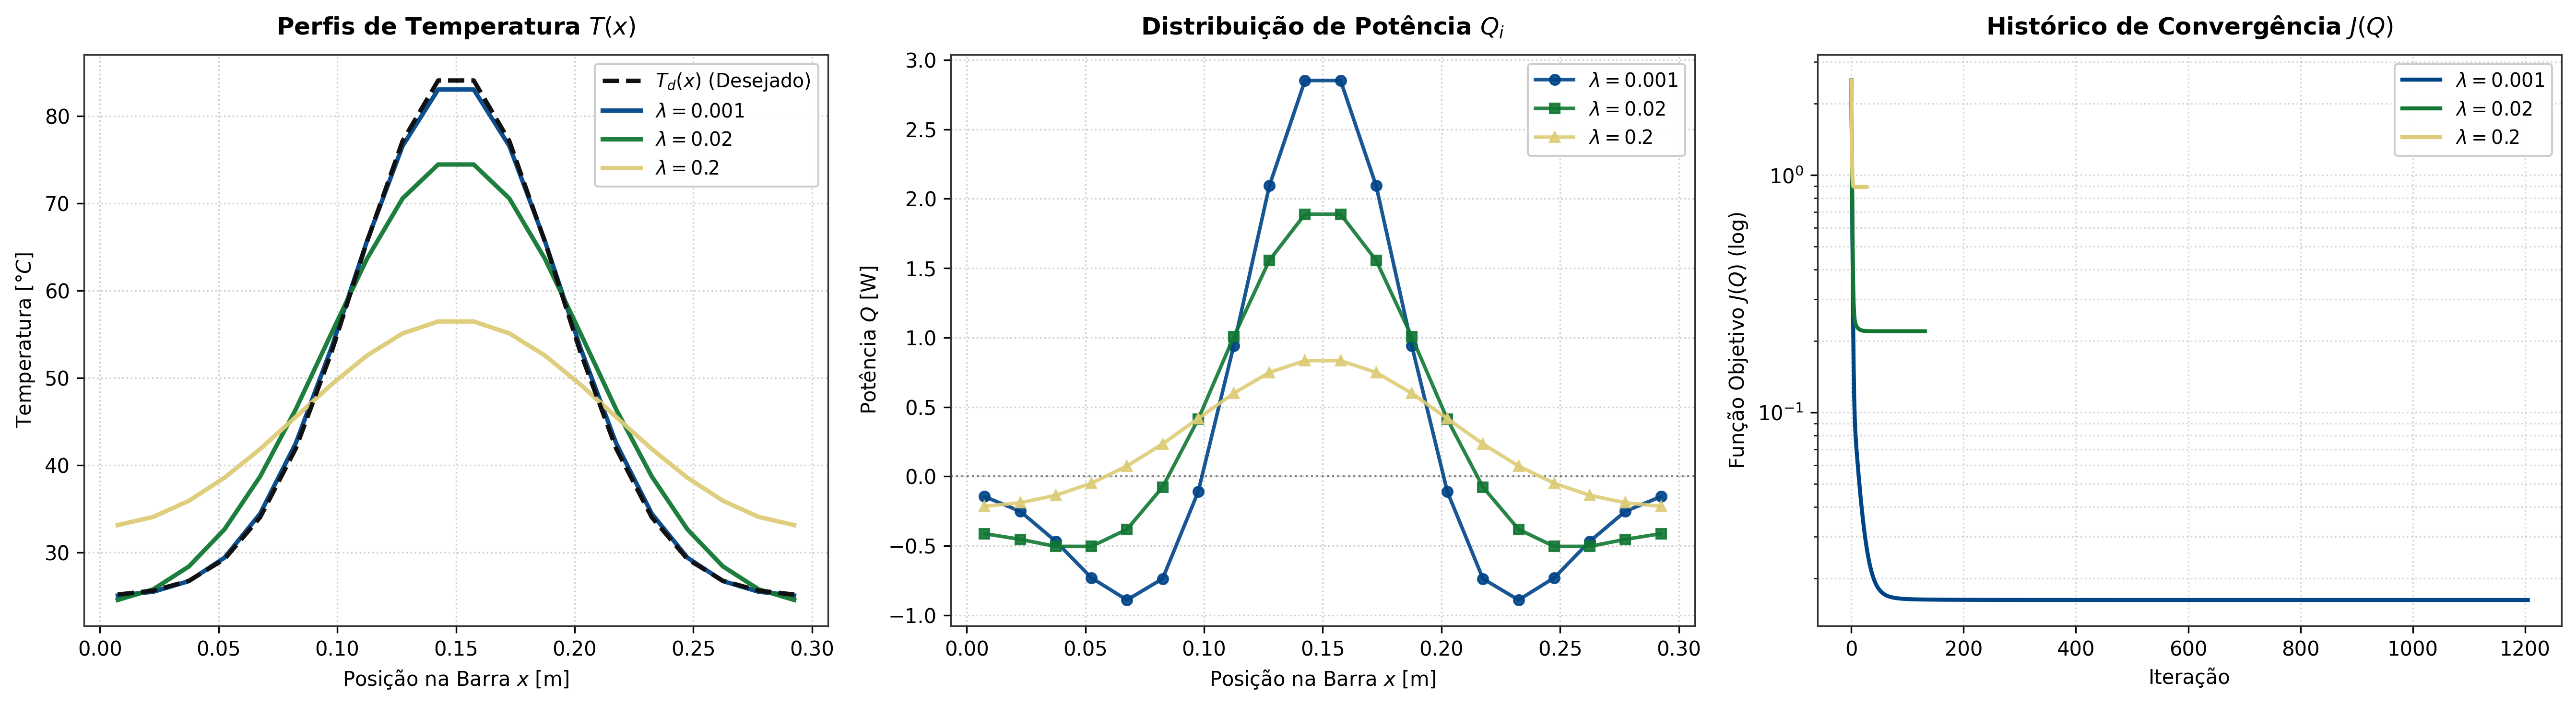

In [20]:
import matplotlib.pyplot as plt

# =============================================================================
# 7. GERAÇÃO DOS GRÁFICOS (PALETA CIENTÍFICA PUBLISH-READY)
# =============================================================================

# Estilo neutro e elegante (padrão de artigo científico)
plt.style.use('default')

fig, axs = plt.subplots(1, 3, figsize=(18, 5), dpi=300)

# Paleta Científica Paul Tol / Cividis (Alta legibilidade e amigável para daltonismo)
# Azul Escuro Profundo (0.001) | Teal / Azul-Esverdeado (0.02) | Amarelo-Escuro / Âmbar (0.2)
cores = {0.001: '#004488', 0.02: '#117733', 0.2: '#DDCC77'}
marcadores = {0.001: 'o', 0.02: 's', 0.2: '^'}

# -----------------------------------------------------------------------------
# Subplot (a): Perfis de Temperatura
# -----------------------------------------------------------------------------
axs[0].plot(x, Td, color='#111111', linestyle='--', label=r'$T_d(x)$ (Desejado)', linewidth=2.2, zorder=5)

for lmb in lambdas:
    axs[0].plot(
        x, resultados[lmb]['T'],
        label=rf'$\lambda = {lmb}$',
        color=cores[lmb],
        linewidth=2.2,
        alpha=0.95
    )

axs[0].set_title('Perfis de Temperatura $T(x)$', fontsize=12, fontweight='bold', pad=10)
axs[0].set_xlabel('Posição na Barra $x$ [m]', fontsize=10)
axs[0].set_ylabel('Temperatura [$°C$]', fontsize=10)
axs[0].grid(True, linestyle=':', alpha=0.6, color='#b0b0b0')
axs[0].legend(frameon=True, edgecolor='#cccccc', facecolor='white', framealpha=0.95, fontsize=9.5)

# -----------------------------------------------------------------------------
# Subplot (b): Potências Aplicadas
# -----------------------------------------------------------------------------
axs[1].axhline(0, color='#666666', linestyle=':', linewidth=1.0, alpha=0.8)

for lmb in lambdas:
    axs[1].plot(
        x, resultados[lmb]['Q'],
        marker=marcadores[lmb],
        linestyle='-',
        label=rf'$\lambda = {lmb}$',
        color=cores[lmb],
        linewidth=1.8,
        markersize=5,
        alpha=0.9
    )

axs[1].set_title('Distribuição de Potência $Q_i$', fontsize=12, fontweight='bold', pad=10)
axs[1].set_xlabel('Posição na Barra $x$ [m]', fontsize=10)
axs[1].set_ylabel('Potência $Q$ [W]', fontsize=10)
axs[1].grid(True, linestyle=':', alpha=0.6, color='#b0b0b0')
axs[1].legend(frameon=True, edgecolor='#cccccc', facecolor='white', framealpha=0.95, fontsize=9.5)

# -----------------------------------------------------------------------------
# Subplot (c): Histórico de Convergência de J
# -----------------------------------------------------------------------------
for lmb in lambdas:
    axs[2].semilogy(
        resultados[lmb]['J'],
        label=rf'$\lambda = {lmb}$',
        color=cores[lmb],
        linewidth=2.0
    )

axs[2].set_title('Histórico de Convergência $J(Q)$', fontsize=12, fontweight='bold', pad=10)
axs[2].set_xlabel('Iteração', fontsize=10)
axs[2].set_ylabel('Função Objetivo $J(Q)$ (log)', fontsize=10)
axs[2].grid(True, which='both', linestyle=':', alpha=0.5, color='#b0b0b0')
axs[2].legend(frameon=True, edgecolor='#cccccc', facecolor='white', framealpha=0.95, fontsize=9.5)

# Ajuste visual das bordas dos gráficos (spines)
for ax in axs:
    for spine in ax.spines.values():
        spine.set_color('#333333')
        spine.set_linewidth(0.8)

plt.tight_layout()
plt.show()